===== Fit results (Task 1) =====
U_q  = 2.6613 V ± 0.0125 V
R_i  = 75.2795 Ω ± 0.6796 Ω
I_k  = 35.35 mA ± 0.36 mA


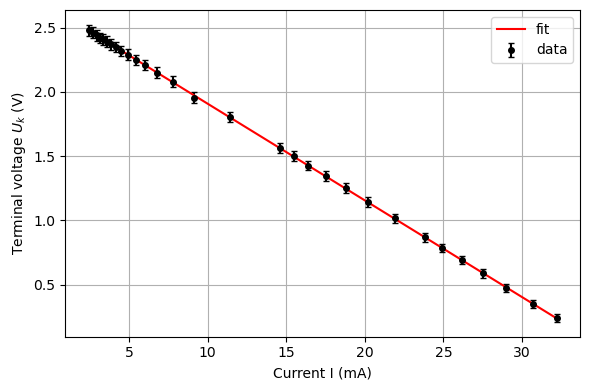

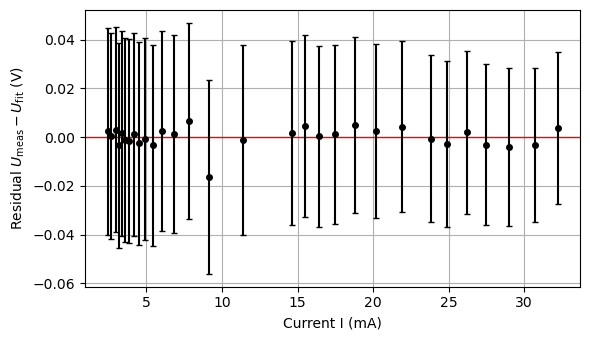

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# ============================
# 1. Load data from CSV
# ============================

# Adjust filename/path if needed
file_name = "Task 1.csv"
df = pd.read_csv(file_name)

# In case the column names differ slightly, we take by column index
R_ohm = df.iloc[:, 0].to_numpy(dtype=float)        # Resistance in ohm
U_V   = df.iloc[:, 1].to_numpy(dtype=float)        # Voltage in volt
I_mA  = df.iloc[:, 2].to_numpy(dtype=float)        # Current in mA

# Convert current to ampere
I_A = I_mA * 1e-3

# ============================
# 2. Uncertainties from manual
# ============================
# Manual (p.3):
# DC-Volt 2, 20, 200 V: ±(0.5% + 3 Digit)
# DC-Ampere 200 mA:    ±(1.2% + 4 Digit)
#
# We used:
#   Voltage range: 20 V  -> digit size = 0.01 V
#   Current range: 200 mA -> digit size = 0.1 mA

VOLT_DIGIT = 0.01   # V per digit on 20 V range
CURR_DIGIT = 0.1    # mA per digit on 200 mA range

# Voltage uncertainty (in V)
dU_V = 0.005 * U_V + 3 * VOLT_DIGIT

# Current uncertainty (in mA)
dI_mA = 0.012 * I_mA + 4 * CURR_DIGIT
# Convert to A
dI_A = dI_mA * 1e-3

# ============================
# 3. Weighted linear fit U(I)
# ============================
# Model: U_k = U_q - R_i * I

def U_model(I, U_q, R_i):
    return U_q - R_i * I

# We treat the uncertainty of U as the dominant one for the fit
sigma_U = dU_V.copy()

popt, pcov = curve_fit(
    U_model,
    I_A,
    U_V,
    sigma=sigma_U,
    absolute_sigma=True
)
U_q_fit, R_i_fit = popt
dU_q_fit, dR_i_fit = np.sqrt(np.diag(pcov))

# Short-circuit current and its uncertainty
I_k_fit = U_q_fit / R_i_fit

# Error propagation: I_k = U_q / R_i
rel_I_k_err = np.sqrt((dU_q_fit / U_q_fit) ** 2 + (dR_i_fit / R_i_fit) ** 2)
dI_k_fit = I_k_fit * rel_I_k_err

print("===== Fit results (Task 1) =====")
print(f"U_q  = {U_q_fit:.4f} V ± {dU_q_fit:.4f} V")
print(f"R_i  = {R_i_fit:.4f} Ω ± {dR_i_fit:.4f} Ω")
print(f"I_k  = {I_k_fit*1e3:.2f} mA ± {dI_k_fit*1e3:.2f} mA")

# ============================
# 4. Fitted curve & residuals
# ============================

# Generate smoother I-grid for plotting the fit
I_fit = np.linspace(I_A.min(), I_A.max(), 400)
U_fit = U_model(I_fit, U_q_fit, R_i_fit)

# Residuals (measured - fitted at measured points)
U_fit_meas = U_model(I_A, U_q_fit, R_i_fit)
residuals = U_V - U_fit_meas

# ============================
# 5. Plot: U vs I with fit
# ============================

plt.figure(figsize=(6, 4))
# Data: black points with error bars
plt.errorbar(
    I_A * 1e3,            # convert to mA for nicer axis
    U_V,
    yerr=dU_V,
    fmt="o",
    markersize=4,
    linestyle="none",
    ecolor="k",
    capsize=2,
    color="k",
    label="data"
)
# Fit: red line
plt.plot(I_fit * 1e3, U_fit, "r-", label="fit")   # I in mA

plt.xlabel("Current I (mA)")
plt.ylabel("Terminal voltage $U_k$ (V)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("task1_UI_fit.png", dpi=300)

# ============================
# 6. Plot: residuals
# ============================

plt.figure(figsize=(6, 3.5))
plt.axhline(0, color="r", linewidth=1)
plt.errorbar(
    I_A * 1e3,
    residuals,
    yerr=sigma_U,
    fmt="o",
    markersize=4,
    linestyle="none",
    ecolor="k",
    capsize=2,
    color="k"
)

plt.xlabel("Current I (mA)")
plt.ylabel("Residual $U_\\text{meas} - U_\\text{fit}$ (V)")
plt.grid(True)

plt.tight_layout()
plt.savefig("task1_residuals.png", dpi=300)

plt.show()

===== Fit results (Task 2) =====
U_q   = 3.3864 V ± 0.0662 V
R_i   = 152.3361 Ω ± 6.6155 Ω
R_a,max (≈ R_i) = 152.3361 Ω ± 6.6155 Ω
P_max = 18.820 mW ± 1.100 mW


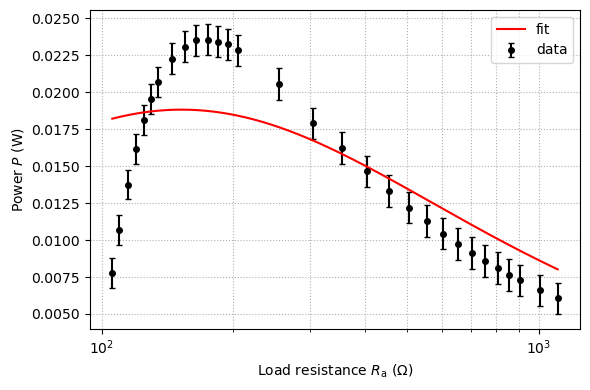

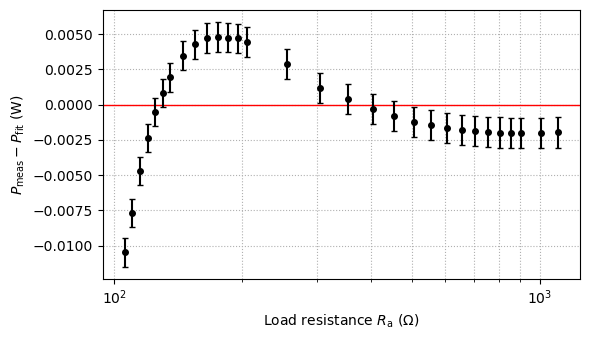

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# ======================================================
# 1. Load Task 1 data (same CSV as before)
# ======================================================

file_name = "Task 1.csv"   # adjust path if needed
df = pd.read_csv(file_name)

R_L = df.iloc[:, 0].to_numpy(dtype=float)      # load resistor (Ω)
U_V = df.iloc[:, 1].to_numpy(dtype=float)      # terminal voltage (V)
I_mA = df.iloc[:, 2].to_numpy(dtype=float)     # current (mA)

I_A = I_mA * 1e-3                              # current in A

# ======================================================
# 2. Uncertainties from manual (same as Task 1)
# ======================================================
# DC-Volt 2, 20, 200 V : ±(0.5% + 3 Digit), 20 V range, digit = 0.01 V
# DC-Ampere 200 mA     : ±(1.2% + 4 Digit), digit = 0.1 mA

VOLT_DIGIT = 0.01   # V
CURR_DIGIT = 0.1    # mA

dU_V = 0.005 * U_V + 3 * VOLT_DIGIT              # in V
dI_mA = 0.012 * I_mA + 4 * CURR_DIGIT            # in mA
dI_A = dI_mA * 1e-3                               # in A

# ======================================================
# 3. Load resistance including ammeter (Task 2)
# ======================================================

R_A = 104.8      # internal resistance of ammeter in ohms (given)
R_a = R_L + R_A  # total load resistance in ohms

# ======================================================
# 4. Power and its uncertainty
# ======================================================

P_W = U_V * I_A     # power in W

# Error propagation: P = U * I
# dP = sqrt( (I dU)^2 + (U dI)^2 )
dP_W = np.sqrt((I_A * dU_V)**2 + (U_V * dI_A)**2)

# ======================================================
# 5. Nonlinear model and weighted fit
# ======================================================

def P_model(Ra, U_q, R_i):
    """Power dissipated in the load as function of load resistance."""
    return (U_q**2 * Ra) / (Ra + R_i)**2

# initial guesses (can use Task 1 results as reasonable starting values)
U_q_guess = 2.66
R_i_guess = 75.0

sigma_P = dP_W.copy()

popt, pcov = curve_fit(
    P_model,
    R_a,
    P_W,
    p0=[U_q_guess, R_i_guess],
    sigma=sigma_P,
    absolute_sigma=True,
    maxfev=10000
)

U_q_fit, R_i_fit = popt
dU_q_fit, dR_i_fit = np.sqrt(np.diag(pcov))

# Maximum power and its location (analytical)
R_a_max = R_i_fit                      # maximum at Ra = Ri
dR_a_max = dR_i_fit                    # same uncertainty

P_max = U_q_fit**2 / (4 * R_i_fit)

# Error propagation for P_max(U_q, R_i)
# P_max = U_q^2 / (4 R_i)
# ∂P/∂U_q = U_q / (2 R_i)
# ∂P/∂R_i = -U_q^2 / (4 R_i^2)
dP_max = np.sqrt(
    (U_q_fit / (2 * R_i_fit))**2 * dU_q_fit**2
    + (-U_q_fit**2 / (4 * R_i_fit**2))**2 * dR_i_fit**2
)

print("===== Fit results (Task 2) =====")
print(f"U_q   = {U_q_fit:.4f} V ± {dU_q_fit:.4f} V")
print(f"R_i   = {R_i_fit:.4f} Ω ± {dR_i_fit:.4f} Ω")
print(f"R_a,max (≈ R_i) = {R_a_max:.4f} Ω ± {dR_a_max:.4f} Ω")
print(f"P_max = {P_max*1e3:.3f} mW ± {dP_max*1e3:.3f} mW")

# ======================================================
# 6. Curves for plotting
# ======================================================

# Use log-spaced Ra for a smooth curve covering the range
Ra_min = R_a.min()
Ra_max_plot = R_a.max()
Ra_fit = np.logspace(np.log10(Ra_min), np.log10(Ra_max_plot), 400)
P_fit = P_model(Ra_fit, U_q_fit, R_i_fit)

# Residuals (measured - fitted at the measured points)
P_fit_meas = P_model(R_a, U_q_fit, R_i_fit)
residuals = P_W - P_fit_meas

# ======================================================
# 7. Plot: P vs Ra (logarithmic x-axis)
# ======================================================

plt.figure(figsize=(6, 4))
# data with error bars (black)
plt.errorbar(
    R_a,
    P_W,
    yerr=dP_W,
    fmt="o",
    markersize=4,
    linestyle="none",
    ecolor="k",
    capsize=2,
    color="k",
    label="data"
)
# fit curve (red)
plt.plot(Ra_fit, P_fit, "r-", label="fit")

plt.xscale("log")
plt.xlabel(r"Load resistance $R_\mathrm{a}$ (Ω)")
plt.ylabel(r"Power $P$ (W)")
plt.legend()
plt.grid(True, which="both", ls=":")

plt.tight_layout()
plt.savefig("task2_P_Ra_fit.png", dpi=300)

# ======================================================
# 8. Plot: residuals vs Ra (logarithmic x-axis)
# ======================================================

plt.figure(figsize=(6, 3.5))
plt.axhline(0.0, color="r", linewidth=1)

plt.errorbar(
    R_a,
    residuals,
    yerr=dP_W,
    fmt="o",
    markersize=4,
    linestyle="none",
    ecolor="k",
    capsize=2,
    color="k"
)

plt.xscale("log")
plt.xlabel(r"Load resistance $R_\mathrm{a}$ (Ω)")
plt.ylabel(r"$P_\mathrm{meas} - P_\mathrm{fit}$ (W)")
plt.grid(True, which="both", ls=":")

plt.tight_layout()
plt.savefig("task2_residuals.png", dpi=300)

plt.show()

===== Solar Cell Characteristic (Task 3) =====
Short-circuit current I_sc  ≈ 3.310 mA ± 0.056 mA at U ≈ 0.051 V
Open-circuit voltage U_oc   ≈ 4.960 V ± 0.055 V at I ≈ 0.489 mA

----- Maximum Power Point (Operating Point) -----
R_mpp = 1000.0 Ω
U_mpp = 3.100 V
I_mpp = 3.040 mA
P_mpp = 9.424 mW ± 0.218 mW


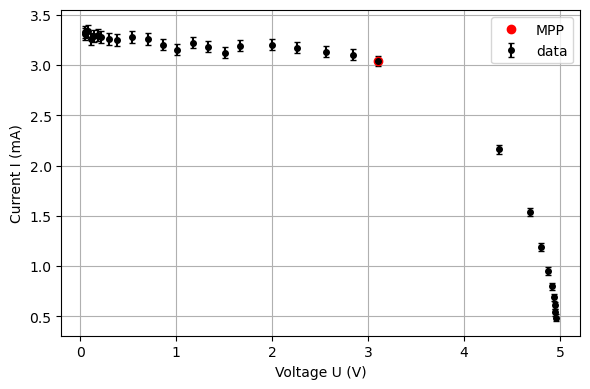

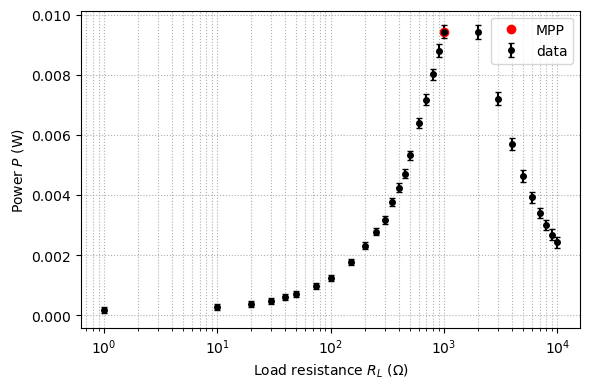

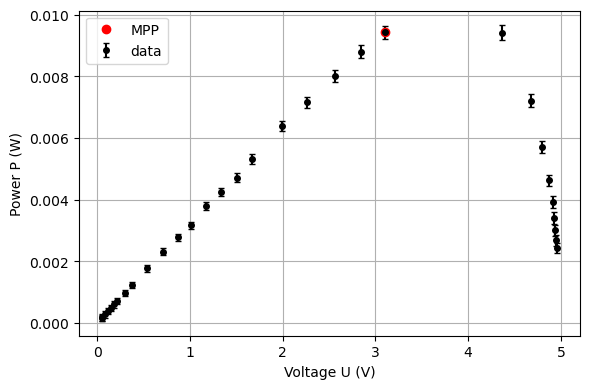

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ======================================================
# 1. Load Task 3 data (solar cell)
# ======================================================

file_name = "Task 3.csv"   # adjust path if needed
df = pd.read_csv(file_name)

R_L = df.iloc[:, 0].to_numpy(dtype=float)      # Load resistance in ohms
U_V = df.iloc[:, 1].to_numpy(dtype=float)      # Voltage in V
I_mA = df.iloc[:, 2].to_numpy(dtype=float)     # Current in mA

I_A = I_mA * 1e-3                              # Current in A

# ======================================================
# 2. Uncertainties from manual (p.3)
# ======================================================
# DC-Volt 2, 20, 200 V : ±(0.5% + 3 Digit), 20 V range, digit = 0.01 V
# DC-Ampere 2, 20 mA   : ±(0.8% + 3 Digit), 20 mA range, digit = 0.01 mA

VOLT_DIGIT = 0.01   # V
CURR_DIGIT = 0.01   # mA

# Voltage uncertainty (V)
dU_V = 0.005 * U_V + 3 * VOLT_DIGIT

# Current uncertainty (mA)
dI_mA = 0.008 * I_mA + 3 * CURR_DIGIT
# Convert to A
dI_A = dI_mA * 1e-3

# ======================================================
# 3. Power and its uncertainty
# ======================================================

P_W = U_V * I_A   # Power in W

# Error propagation: P = U * I
# dP = sqrt( (I dU)^2 + (U dI)^2 )
dP_W = np.sqrt((I_A * dU_V)**2 + (U_V * dI_A)**2)

# ======================================================
# 4. Key characteristic points
# ======================================================

# Short-circuit current (R=0)   -> first row in your data
I_sc = I_A[0]
dI_sc = dI_A[0]
U_sc = U_V[0]

# Open-circuit voltage (largest R) -> last row in your data
U_oc = U_V[-1]
dU_oc = dU_V[-1]
I_oc = I_A[-1]

# Maximum power point (operating point)
idx_mpp = np.argmax(P_W)
R_mpp = R_L[idx_mpp]
U_mpp = U_V[idx_mpp]
I_mpp = I_A[idx_mpp]
P_mpp = P_W[idx_mpp]
dP_mpp = dP_W[idx_mpp]

print("===== Solar Cell Characteristic (Task 3) =====")
print(f"Short-circuit current I_sc  ≈ {I_sc*1e3:.3f} mA ± {dI_sc*1e3:.3f} mA at U ≈ {U_sc:.3f} V")
print(f"Open-circuit voltage U_oc   ≈ {U_oc:.3f} V ± {dU_oc:.3f} V at I ≈ {I_oc*1e3:.3f} mA")
print()
print("----- Maximum Power Point (Operating Point) -----")
print(f"R_mpp = {R_mpp:.1f} Ω")
print(f"U_mpp = {U_mpp:.3f} V")
print(f"I_mpp = {I_mpp*1e3:.3f} mA")
print(f"P_mpp = {P_mpp*1e3:.3f} mW ± {dP_mpp*1e3:.3f} mW")

# ======================================================
# 5. I–V characteristic plot
# ======================================================

plt.figure(figsize=(6, 4))

# Current vs Voltage with error bars (black)
plt.errorbar(
    U_V,
    I_mA,                  # keep in mA for readability
    yerr=dI_mA,
    fmt="o",
    markersize=4,
    linestyle="none",
    ecolor="k",
    capsize=2,
    color="k",
    label="data"
)

# Mark maximum power point in red
plt.plot(U_mpp, I_mpp*1e3, "ro", label="MPP")

plt.xlabel("Voltage U (V)")
plt.ylabel("Current I (mA)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("task3_IV_curve.png", dpi=300)

# ======================================================
# 6. Power vs load resistance (P–R diagram, log x-axis)
# ======================================================

plt.figure(figsize=(6, 4))

plt.errorbar(
    R_L,
    P_W,
    yerr=dP_W,
    fmt="o",
    markersize=4,
    linestyle="none",
    ecolor="k",
    capsize=2,
    color="k",
    label="data"
)

# Mark maximum power point
plt.plot(R_mpp, P_mpp, "ro", label="MPP")

plt.xscale("log")
plt.xlabel(r"Load resistance $R_L$ (Ω)")
plt.ylabel(r"Power $P$ (W)")
plt.legend()
plt.grid(True, which="both", ls=":")

plt.tight_layout()
plt.savefig("task3_P_RL_curve.png", dpi=300)

# ======================================================
# 7. Power vs voltage (optional but useful)
# ======================================================

plt.figure(figsize=(6, 4))

plt.errorbar(
    U_V,
    P_W,
    yerr=dP_W,
    fmt="o",
    markersize=4,
    linestyle="none",
    ecolor="k",
    capsize=2,
    color="k",
    label="data"
)

plt.plot(U_mpp, P_mpp, "ro", label="MPP")

plt.xlabel("Voltage U (V)")
plt.ylabel("Power P (W)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("task3_P_V_curve.png", dpi=300)

plt.show()